# Serie de tren de pulsos rectangulares impar

#### Calculo de la serie

In [1]:
from sympy import*

In [2]:
x = Symbol('x')
w = Piecewise((-1, (x > -1) & (x < 0)), (1, (x >= 0) & (x < 1)))
w

Piecewise((-1, (x > -1) & (x < 0)), (1, (x >= 0) & (x < 1)))

In [3]:
s = fourier_series(w, (x, -1, 1))
s5 = s.truncate(n = 5)
s5

4*sin(pi*x)/pi + 4*sin(3*pi*x)/(3*pi) + 4*sin(5*pi*x)/(5*pi) + 4*sin(7*pi*x)/(7*pi) + 4*sin(9*pi*x)/(9*pi)

#### Gráfica de convergencia de la serie

In [4]:
%matplotlib inline   
from matplotlib import pyplot as plt
import numpy as np
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

ModuleNotFoundError: No module named 'ipywidgets'

In [ ]:
def Serie_Fourier(N):
    sf = 0; 
    for k in range (0, N, 1): # n 1, 3, 5, 7, ...
        def arms(t):
            return 4*np.sin((2*k + 1)*np.pi*t)/((2*k +1)*np.pi)
        t = np.linspace(-2, 2, 1000)
        sf += arms(t)
    plt.plot(t, sf, 'k')

In [ ]:
interact(Serie_Fourier, N = (1, 10)) # N=1 fundamental, N=2 fundamental + tercera arm, etc  

interactive(children=(IntSlider(value=5, description='N', max=10, min=1), Output()), _dom_classes=('widget-int…

<function __main__.Serie_Fourier(N)>

#### Gráficas de armónicas de la serie

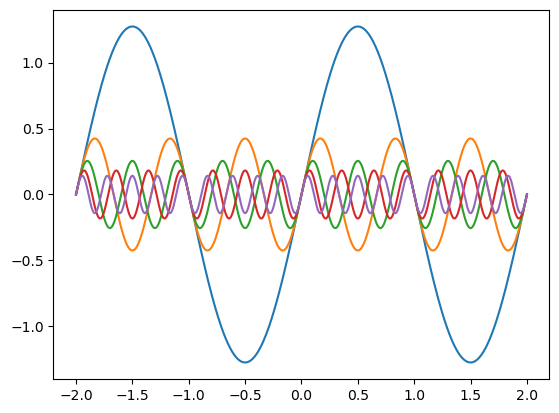

In [ ]:
for k in range (5):
    def arms(t):
        return 4*np.sin((2*k + 1)*np.pi*t)/((2*k +1)*np.pi)
        t = np.linspace (-2, 2, 1000)
    plt.plot(t, [arms(i) for i in t])

#### Gráfica del espectro usando fft

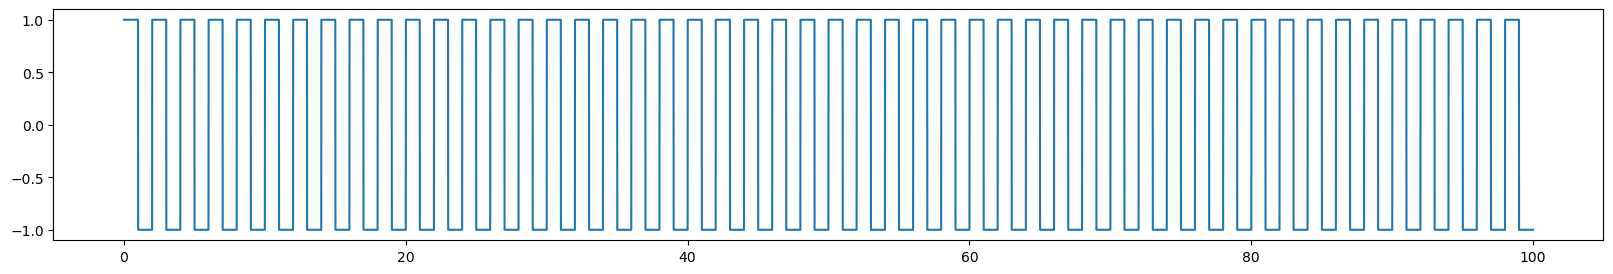

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
dt = 0.01 #seg
t = np.arange(0.0, 100.0, dt)
#T1 = 4.0 # seg, períod0
#f1 = 1/T1 # frecuencia
s = np.sin(np.pi*t)
x = 2*np.floor(0.8*s+1)-1
plt.figure(figsize = (20, 3))
plt.plot(t, x)

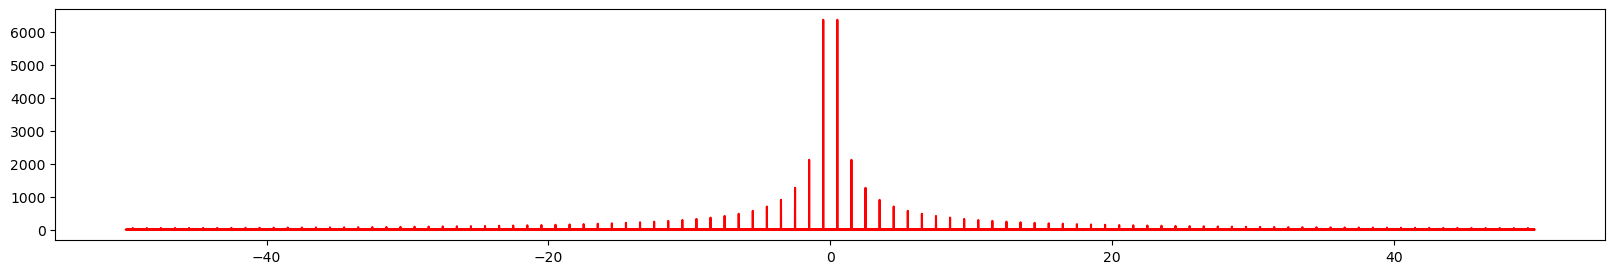

In [ ]:
X = np.fft.fft(x)
freq = np.fft.fftfreq(np.size(X), d = dt)
plt.figure(figsize = (20, 3))
plt.plot(freq, np.abs(X), "r")

##### En términos de energía se demuestra y dice que el tren de pulsos cuadrados tiene energia a frecuencias fundamental e impares. No tiene energía a frecuencias pares. A medida que crece la frencuencia su energía disminuye, es decir es de baja frecuencia.  